# Creep on the San Andreas Fault

**Frame F11116 (central California), 2016-07 to 2026-04, 389 granules.**
Between San Juan Bautista and Parkfield the San Andreas Fault creeps at the
surface: the Pacific side slides northwest past the North American side at
about 2.5 cm/yr, with no earthquakes to lock it. A creeping fault shows in
a velocity map as a sharp step along the trace.

This notebook takes a 45 x 40 km window across the creeping section near
Slack Canyon, estimates velocities, and measures the step against what
26 mm/yr of right-lateral creep looks like in this frame's line of sight.

This notebook ran on real granules; its outputs are saved, and the
documentation build does not run it again.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from pyproj import Transformer

import disp_xr as dxr
from disp_xr.product import MixedPrecisionWarning

warnings.simplefilter("ignore", FutureWarning)
# The frame spans the November 2025 production change; see the
# production-change notebook.
warnings.simplefilter("ignore", MixedPrecisionWarning)
frame = Path("/u/aurora-r0/govorcin/01_OPERA/DISP/data/F11116")
static_dir = Path("/u/aurora-r0/govorcin/01_OPERA/DISP/data/static/F11116")


def title(ax, text):
    """Title the panel on the left, without xarray's automatic title."""
    ax.set_title("")
    ax.set_title(text, loc="left")


raw = dxr.open_disp(frame, layers=["displacement", "recommended_mask"])
west, south, east, north = -120.95, 35.95, -120.45, 36.32
to_grid = Transformer.from_crs("EPSG:4326", raw.rio.crs, always_xy=True)
(x0, x1), (y0, y1) = to_grid.transform([west, east], [south, north])
window = raw.sel(x=slice(x0, x1), y=slice(y1, y0))
print(f"{len(raw.attrs['input_granules'])} granules; window {dict(window.sizes)}")

389 granules; window {'time': 389, 'y': 1404, 'x': 1467}


## The fault trace

A straight line between two points on the fault, San Juan Bautista and
Parkfield, stands in for the trace. In this window the mapped trace stays
within a kilometer or two of it. Every pixel gets a distance along the
fault and across it (positive to the northeast, on the North American
side).

In [2]:
(fx0, fx1), (fy0, fy1) = to_grid.transform([-121.537, -120.433], [36.845, 35.900])
strike = np.array([fx0 - fx1, fy0 - fy1]) / np.hypot(fx0 - fx1, fy0 - fy1)  # to NW
normal = np.array([strike[1], -strike[0]])  # to NE
print(f"strike N{np.degrees(np.arctan2(-strike[0], strike[1])):.0f}W")

dx, dy = window.x - fx1, window.y - fy1
across = ((dx * normal[0] + dy * normal[1]) / 1e3).transpose("y", "x")
along = ((dx * strike[0] + dy * strike[1]) / 1e3).transpose("y", "x")
middle = float(along.sel(x=window.x.mean(), y=window.y.mean(), method="nearest"))

strike N45W


## Velocity

Mask with the recommended mask, chain the ministacks, and reference to a
1 km box on the North American side, 8 km from the trace. MIDAS is robust
to steps and outliers; pixels valid in fewer than half the epochs are left
out.

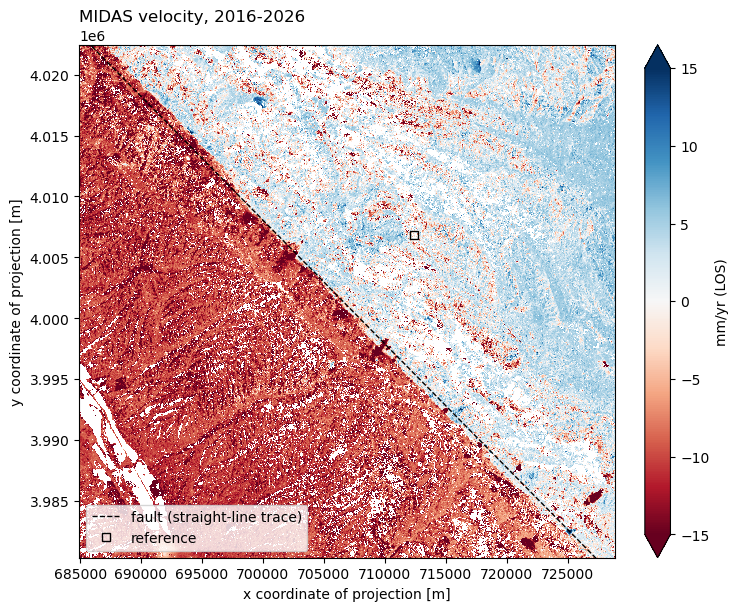

In [3]:
ref_x, ref_y = np.array([fx1, fy1]) + (middle * strike + 8 * normal) * 1e3
to_lonlat = Transformer.from_crs(raw.rio.crs, "EPSG:4326", always_xy=True)
ref_lon, ref_lat = to_lonlat.transform(ref_x, ref_y)

ds = dxr.stack_disp(dxr.mask(window, "recommended"))
ds = dxr.rereference(
    ds,
    "area",
    bbox=(ref_lon - 0.005, ref_lat - 0.005, ref_lon + 0.005, ref_lat + 0.005),
)
ds = ds.persist()  # read the granules once for the velocity and the series below
velocity = dxr.fit_velocity(ds, method="midas").compute()
enough = (
    ds.displacement.isel(time=slice(1, None)).notnull().mean("time").compute() >= 0.5
)
vel = 1e3 * velocity.velocity.where(enough)

fig, ax = plt.subplots(figsize=(7.5, 6), layout="constrained")
vel.plot.imshow(
    ax=ax, cmap="RdBu", vmin=-15, vmax=15, cbar_kwargs={"label": "mm/yr (LOS)"}
)
ax.plot([fx0, fx1], [fy0, fy1], "k--", lw=1, label="fault (straight-line trace)")
ax.plot(ref_x, ref_y, "ks", ms=6, mfc="none", label="reference")
ax.set(xlim=(window.x.min(), window.x.max()), ylim=(window.y.min(), window.y.max()))
ax.set_aspect("equal")
ax.legend(loc="lower left")
title(ax, "MIDAS velocity, 2016-2026")
plt.show()

## What creep looks like in the line of sight

Right-lateral creep moves the Pacific side northwest relative to the North
American side. Projected with the frame's line-of-sight vectors from the
DISP-S1-STATIC layers, 26 mm/yr of horizontal motion along the strike gives
the step expected across the trace.

In [4]:
static = dxr.open_static(ds, static_dir=static_dir)
los = (
    static[["los_east", "los_north", "los_up"]]
    .sel(x=ref_x, y=ref_y, method="nearest")
    .compute()
)
creep = 26.0  # mm/yr, Pacific side relative to North American side
expected = float(dxr.enu_to_los(creep * strike[0], creep * strike[1], 0.0, los))
print(
    f"line of sight (east, north, up): {float(los.los_east):.2f}, "
    f"{float(los.los_north):.2f}, {float(los.los_up):.2f}"
)
print(f"expected step, southwest side minus northeast side: {expected:+.1f} mm/yr")

line of sight (east, north, up): 0.56, -0.10, 0.82
expected step, southwest side minus northeast side: -12.1 mm/yr


## Profile across the fault

Velocities in a 10 km swath centered on the window, binned by distance
from the trace. The step is the difference between the medians 2 to 8 km
on either side.

observed step, southwest side minus northeast side: -11.9 mm/yr


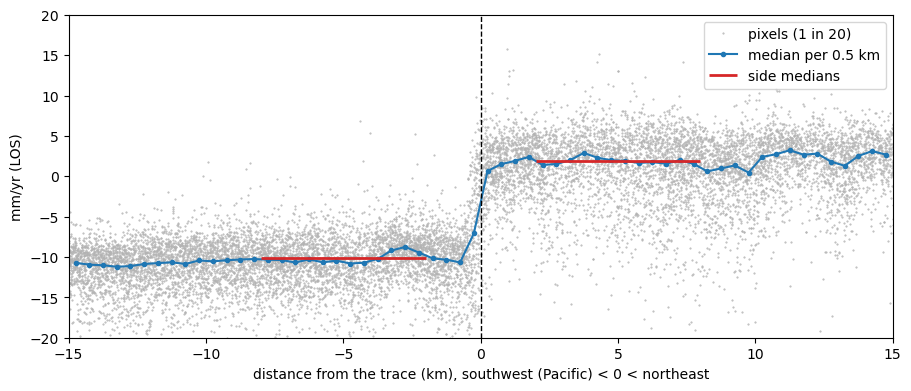

In [5]:
swath = abs(along - middle) < 5
profile = (
    vel.where(swath)
    .rename("velocity")
    .assign_coords(across=across)
    .groupby_bins("across", np.arange(-15, 15.5, 0.5))
    .median()
)
centers = np.array([b.mid for b in profile.across_bins.values])
sw = float(vel.where(swath & (across > -8) & (across < -2)).median())
ne = float(vel.where(swath & (across > 2) & (across < 8)).median())
print(f"observed step, southwest side minus northeast side: {sw - ne:+.1f} mm/yr")

fig, ax = plt.subplots(figsize=(9, 3.8), layout="constrained")
sample = vel.where(swath).values.ravel()
dist = np.broadcast_to(across.values, vel.shape).ravel()
keep = np.isfinite(sample) & (np.arange(sample.size) % 20 == 0)
ax.plot(dist[keep], sample[keep], ".", ms=1, color="0.7", label="pixels (1 in 20)")
ax.plot(centers, profile.values, "o-", ms=3, color="C0", label="median per 0.5 km")
ax.hlines([sw, ne], [-8, 2], [-2, 8], colors="C3", lw=2, label="side medians")
ax.axvline(0, color="k", ls="--", lw=1)
ax.set(
    xlabel="distance from the trace (km), southwest (Pacific) < 0 < northeast",
    ylabel="mm/yr (LOS)",
    xlim=(-15, 15),
    ylim=(-20, 20),
)
ax.legend(loc="upper right")
plt.show()

## Creep through time

The difference between the two sides of the swath, 2 to 8 km from the
trace, removes what they share (the reference, most of the troposphere)
and leaves the slip across the fault.

Only pixels valid in at least 80% of epochs are used. A pixel masked at an
epoch that links two ministacks cannot be chained past it, so in the
chained stack it stays empty from there on; a median over a few such
pixels would jump as they drop out.

-8 to -2 km: 51023 pixels
+2 to +8 km: 44076 pixels


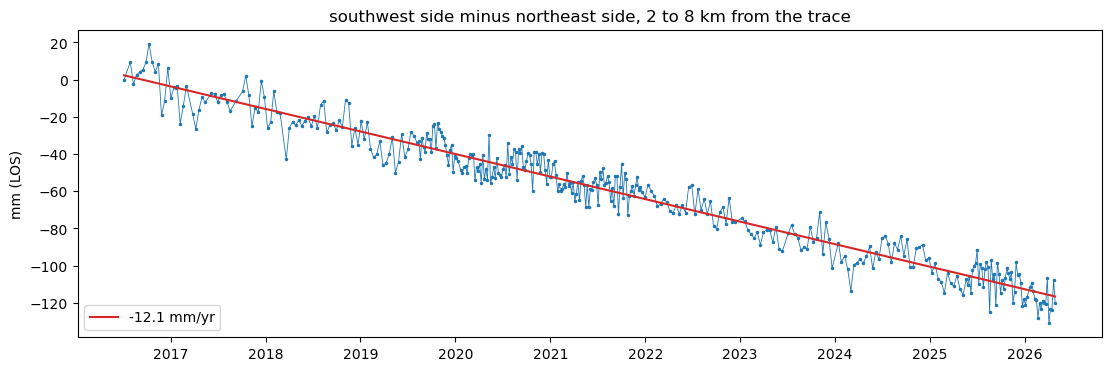

In [6]:
reliable = ds.displacement.notnull().mean("time").compute() >= 0.8


def side_series(lo, hi):
    """Median displacement per epoch of reliable swath pixels `lo` to `hi` km across."""
    region = swath & (across > lo) & (across < hi) & reliable
    print(f"{lo:+d} to {hi:+d} km: {int(region.sum())} pixels")
    return ds.displacement.where(region).median(("y", "x"))


slip = (1e3 * (side_series(-8, -2) - side_series(2, 8))).compute().dropna("time")
years = (slip.time - slip.time[0]).dt.days / 365.25
rate, offset = np.polyfit(years, slip, 1)

fig, ax = plt.subplots(figsize=(11, 3.6), layout="constrained")
ax.plot(slip.time, slip, ".-", ms=3, lw=0.6)
ax.plot(slip.time, offset + rate * years, "C3", label=f"{rate:+.1f} mm/yr")
ax.set(
    ylabel="mm (LOS)",
    title="southwest side minus northeast side, 2 to 8 km from the trace",
)
ax.legend(loc="lower left")
plt.show()

A steady rate with no steps is what creep looks like. Earthquakes on the
locked sections to the north and south, or a slow-slip event, would show
as offsets; the residual scatter is troposphere and noise the two sides do
not share.